# Queueing systems

*Beyond the exercises — chapter 7 of the scriptum.*

---

A queue at a till, requests to a server, patients in a waiting room, packets in a router. The common
scheme: **requests arrive at random, service takes a random length of time, and in between there is
waiting**.

The model is a close relative of the insurance company from exercises 2 and 9 — there too, claims
arrived at random moments. The difference is that now we care not just about the total but about the
**course in time**: how many people are standing in the queue and how long they wait.

- the **M/M/1** model and what those three letters mean
- two ways to simulate it: the **$\Delta t$ model** and the **discrete-event model** — and why the
  second one is better
- a verification against the exact formulas
- what happens when the load approaches one
- the **transient**: why the beginning of a run has to be thrown away

In [1]:
import heapq
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # reproducible results


def exponential(lam):
    return -math.log(1.0 - random.random()) / lam

## 1. The M/M/1 model

The notation **A/B/c** (Kendall): A = the arrivals, B = the service, c = the number of servers.

**M/M/1** means:

- **M**arkovian arrivals: the gaps between arrivals are $\operatorname{Exp}(\lambda)$, so the arrivals
  form a Poisson process of intensity $\lambda$ (exercise 3),
- **M**arkovian service: the service time is $\operatorname{Exp}(\mu)$,
- **1** server, an unlimited queue, served in order of arrival (FIFO).

The key parameter is the **load**

$$\varrho = \frac{\lambda}{\mu}.$$

For $\varrho \ge 1$ work arrives faster than it can be dispatched, and the queue grows without bound.
For $\varrho < 1$ the system settles down and exact formulas hold:

| Quantity | Formula |
|---|---|
| $P(n \text{ requests in the system})$ | $(1-\varrho)\varrho^{\,n}$ |
| mean number in the system $L$ | $\dfrac{\varrho}{1-\varrho}$ |
| mean number in the queue $L_q$ | $\dfrac{\varrho^2}{1-\varrho}$ |
| mean time in the system $W$ | $\dfrac{1}{\mu - \lambda}$ |
| mean waiting time $W_q$ | $\dfrac{\varrho}{\mu - \lambda}$ |

**Little's law** $L = \lambda W$ also holds, which is handy as an independent check.

It is exactly the fact that we know the exact formulas that makes M/M/1 an ideal test problem: we have
something to compare the simulation against.

In [2]:
def theory_mm1(lam, mu):
    rho = lam / mu
    return dict(rho=rho, L=rho / (1 - rho), Lq=rho**2 / (1 - rho),
                W=1 / (mu - lam), Wq=rho / (mu - lam))


for lam, mu in ((0.5, 1.0), (0.8, 1.0), (0.95, 1.0)):
    t = theory_mm1(lam, mu)
    print(f"λ = {lam}, μ = {mu}:  ϱ = {t['rho']:.2f}   L = {t['L']:6.2f}   W = {t['W']:6.2f}   Wq = {t['Wq']:6.2f}")

λ = 0.5, μ = 1.0:  ϱ = 0.50   L =   1.00   W =   2.00   Wq =   1.00
λ = 0.8, μ = 1.0:  ϱ = 0.80   L =   4.00   W =   5.00   Wq =   4.00
λ = 0.95, μ = 1.0:  ϱ = 0.95   L =  19.00   W =  20.00   Wq =  19.00


## 2. Two ways to simulate such a system

### The $\Delta t$ model

The most straightforward idea: slice time into short stretches $\Delta t$ and in each one ask what
happened. With probability $\lambda\Delta t$ a request arrives, with probability $\mu\Delta t$ a
service finishes.

It is the very procedure by which exercise 2 sliced the year into days. And it has the same two flaws:

- **It is inaccurate.** More than one event can happen within a single $\Delta t$, but the model
  admits at most one. The error only vanishes as $\Delta t \to 0$.
- **It is slow.** Most of the steps are empty; the smaller $\Delta t$, the more empty steps.

### The discrete-event model

A better idea: time does not **flow**, it jumps. We keep a list of scheduled events, always take out
the nearest one, move the clock to it and process it. Between events nothing happens, so there is
nothing to compute.

For M/M/1 two kinds of event suffice: *arrival* and *departure*. The model is **exact** (no
discretization) and takes exactly as many steps as there are events.

Let us write both and compare.

In [3]:
def queue_delta_t(lam, mu, T, dt):
    '''The Δt model: in each step at most one arrival and at most one departure.'''
    n = 0
    sum_n = 0.0
    steps = int(T / dt)
    for _ in range(steps):
        if n > 0 and random.random() < mu * dt:
            n -= 1
        if random.random() < lam * dt:
            n += 1
        sum_n += n * dt
    return sum_n / (steps * dt)           # the time average of the number in the system = L


def queue_events(lam, mu, T, warmup=0.0):
    '''The discrete-event model for M/M/1.

    Returns (L, Lq, W, Wq, P(n), server utilization). The part of the run up to time `warmup`
    is left out of the statistics — see the section on the transient.
    '''
    t = 0.0
    n = 0                                    # the number in the system
    events = [(exponential(lam), "arrival")]
    waiting = []                             # the arrival times of those waiting
    times_in_system = []
    time_in_state = {}
    last = 0.0

    while events:
        tm, kind = heapq.heappop(events)
        if tm > T:
            break
        if tm > warmup:                      # add in the time spent in state n
            since = max(last, warmup)
            time_in_state[n] = time_in_state.get(n, 0.0) + (tm - since)
        last = tm
        t = tm

        if kind == "arrival":
            n += 1
            waiting.append(t)
            heapq.heappush(events, (t + exponential(lam), "arrival"))
            if n == 1:                       # the server was free, start serving at once
                heapq.heappush(events, (t + exponential(mu), "departure"))
        else:
            n -= 1
            arrived = waiting.pop(0)
            if t > warmup:
                times_in_system.append(t - arrived)
            if n > 0:
                heapq.heappush(events, (t + exponential(mu), "departure"))

    total = sum(time_in_state.values())
    P = {k: v / total for k, v in sorted(time_in_state.items())}
    L = sum(k * p for k, p in P.items())
    Lq = sum(max(k - 1, 0) * p for k, p in P.items())
    W = sum(times_in_system) / len(times_in_system)
    return L, Lq, W, W - 1 / mu, P, 1 - P.get(0, 0.0)


lam, mu, T = 0.8, 1.0, 200_000.0
t = theory_mm1(lam, mu)
L, Lq, W, Wq, P, utilization = queue_events(lam, mu, T, warmup=1000.0)

print(f"M/M/1 with λ = {lam}, μ = {mu} (ϱ = {t['rho']}), run length T = "
      + format(T, ",.0f").replace(",", " "))   # the replace only on the number, not on the prose commas
print(f"\n{'quantity':28s} {'simulation':>11s} {'theory':>10s}")
print(f"{'L  (number in system)':28s} {L:>11.4f} {t['L']:>10.4f}")
print(f"{'Lq (number in queue)':28s} {Lq:>11.4f} {t['Lq']:>10.4f}")
print(f"{'W  (time in system)':28s} {W:>11.4f} {t['W']:>10.4f}")
print(f"{'Wq (waiting time)':28s} {Wq:>11.4f} {t['Wq']:>10.4f}")
print(f"{'server utilization':28s} {utilization:>11.4f} {t['rho']:>10.4f}")
print(f"\nLittle's law: L = λW ?   {L:.4f}  vs  {lam * W:.4f}")

M/M/1 with λ = 0.8, μ = 1.0 (ϱ = 0.8), run length T = 200 000

quantity                      simulation     theory
L  (number in system)             3.8340     4.0000
Lq (number in queue)              3.0368     3.2000
W  (time in system)               4.8034     5.0000
Wq (waiting time)                 3.8034     4.0000
server utilization                0.7973     0.8000

Little's law: L = λW ?   3.8340  vs  3.8427


The simulation matches all five formulas and Little's law holds. Now the comparison with the
$\Delta t$ model.

In [4]:
import time

exact_L = t["L"]
REPS, T_SHORT = 12, 20_000.0

print("The error of the Δt model has two parts: a systematic bias from the discretization")
print("and statistical noise. We separate them by averaging several independent runs.\n")
print(f"{'method':24s} {'L (average)':>12s} {'std error':>11s} {'bias':>11s} {'time':>8s}")

dts, bias, errs_se = [], [], []
for dt in (0.5, 0.25, 0.1, 0.05):
    t0 = time.perf_counter()
    res = [queue_delta_t(lam, mu, T_SHORT, dt) for _ in range(REPS)]
    elapsed = (time.perf_counter() - t0)
    m = sum(res) / REPS
    se = math.sqrt(sum((v - m) ** 2 for v in res) / (REPS - 1) / REPS)
    dts.append(dt); bias.append(abs(m - exact_L)); errs_se.append(se)
    print(f"{'Δt = ' + format(dt, '.2f'):24s} {m:>12.3f} {se:>11.3f} {m - exact_L:>+11.3f} {elapsed:>7.1f} s")

t0 = time.perf_counter()
res = [queue_events(lam, mu, T_SHORT, warmup=500.0)[0] for _ in range(REPS)]
t_ev = time.perf_counter() - t0
m_ev = sum(res) / REPS
se_ev = math.sqrt(sum((v - m_ev) ** 2 for v in res) / (REPS - 1) / REPS)
print(f"{'discrete events':24s} {m_ev:>12.3f} {se_ev:>11.3f} {m_ev - exact_L:>+11.3f} {t_ev:>7.1f} s")
print(f"{'theory':24s} {exact_L:>12.3f}")
print(f"\nthe Δt model is biased downwards: in one step it admits at most one arrival")
print(f"and one departure, so it clips the peaks of the queue. The event model has no bias —")
print(f"its deviation ({m_ev - exact_L:+.3f}) is the size of the standard error ({se_ev:.3f}), i.e. consistent with zero.")

The error of the Δt model has two parts: a systematic bias from the discretization
and statistical noise. We separate them by averaging several independent runs.

method                    L (average)   std error        bias     time
Δt = 0.50                       2.471       0.053      -1.529     0.1 s


Δt = 0.25                       3.122       0.081      -0.878     0.1 s


Δt = 0.10                       3.633       0.095      -0.367     0.2 s


Δt = 0.05                       3.839       0.055      -0.161     0.4 s
discrete events                 4.134       0.123      +0.134     0.1 s
theory                          4.000

the Δt model is biased downwards: in one step it admits at most one arrival
and one departure, so it clips the peaks of the queue. The event model has no bias —
its deviation (+0.134) is the size of the standard error (0.123), i.e. consistent with zero.


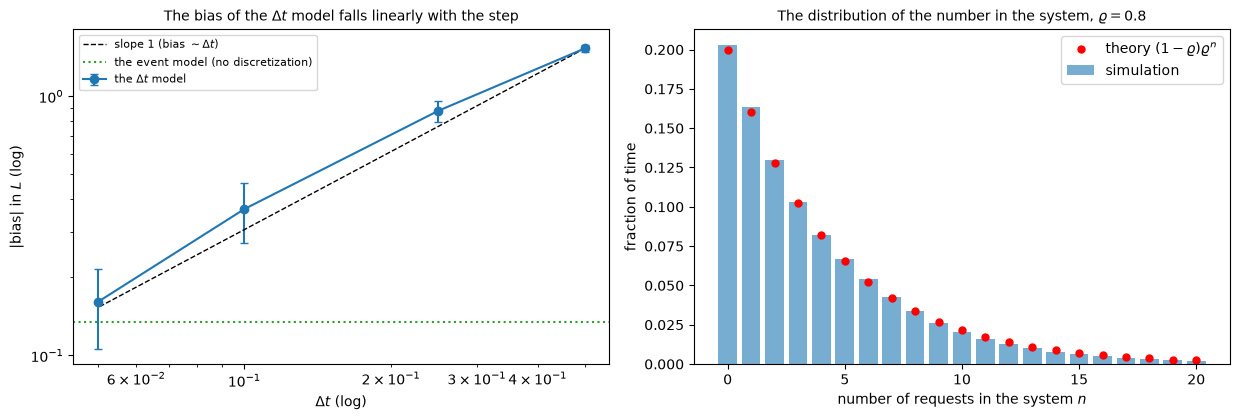

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3))

ax = axes[0]
ax.errorbar(dts, bias, yerr=errs_se, fmt="o-", capsize=3, label="the $\\Delta t$ model")
ax.loglog(dts, [bias[0] * (d / dts[0]) for d in dts], "k--", lw=1,
          label="slope 1 (bias $\\sim \\Delta t$)")
ax.axhline(abs(m_ev - exact_L), color="tab:green", ls=":",
           label="the event model (no discretization)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("$\\Delta t$ (log)")
ax.set_ylabel("$|$bias$|$ in $L$ (log)")
ax.set_title("The bias of the $\\Delta t$ model falls linearly with the step", fontsize=10)
ax.legend(fontsize=8)

ax = axes[1]
ks = sorted(k for k in P if k <= 20)
ax.bar(ks, [P[k] for k in ks], alpha=0.6, label="simulation")
rho = t["rho"]
ax.plot(ks, [(1 - rho) * rho**k for k in ks], "ro", ms=5, label=r"theory $(1-\varrho)\varrho^n$")
ax.set_xlabel("number of requests in the system $n$")
ax.set_ylabel("fraction of time")
ax.set_title(f"The distribution of the number in the system, $\\varrho = {rho}$", fontsize=10)
ax.legend()

plt.tight_layout()
plt.show()

The left-hand plot confirms what was expected: the **bias** of the $\Delta t$ model falls linearly
with the step. At the same time it shows why it was worth separating the bias from the noise — at
$\Delta t = 0.05$ the bias is already smaller than the statistical error of a single run, so from one
run alone it would be invisible.

The discrete-event model has no bias at all (its deviation is within the standard error) and runs
faster than the $\Delta t$ model with a fine step. Better in both respects at once — which is why in
practice it is used almost exclusively.

The right-hand plot shows that the whole **distribution** fits too, not just the means.

## 3. When the load approaches one

The formula $L = \varrho/(1-\varrho)$ has $1 - \varrho$ in the denominator, so as $\varrho \to 1$ it
grows without bound. That is not a mathematical curiosity but an operational reality: **a system
utilized to 95 % has a queue ten times longer than a system utilized to 90 %**.

It is also awkward for the simulation — the closer to one, the more slowly the averages settle, as we
shall see in the right-hand plot below.

     ϱ   L simulation   L theory  rel. error
  0.50          0.997      1.000       0.3%
  0.70          2.377      2.333       1.9%


  0.80          4.054      4.000       1.3%
  0.90          8.709      9.000       3.2%


  0.95         19.421     19.000       2.2%


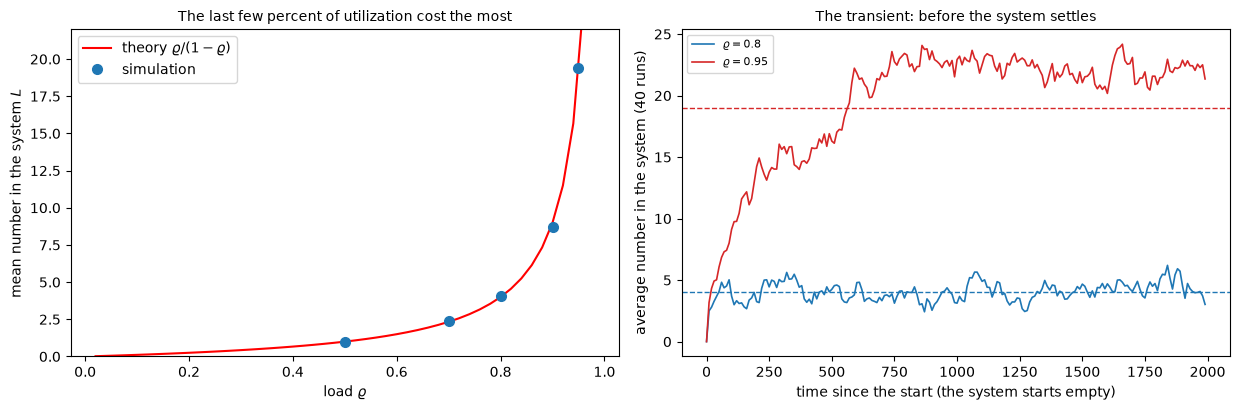

In [6]:
rhos = (0.5, 0.7, 0.8, 0.9, 0.95)
L_sim, L_theory = [], []
print(f"{'ϱ':>6s} {'L simulation':>14s} {'L theory':>10s} {'rel. error':>11s}")
for rho in rhos:
    lam_ = rho
    Lx = queue_events(lam_, 1.0, 300_000.0, warmup=5000.0)[0]
    Lt = rho / (1 - rho)
    L_sim.append(Lx); L_theory.append(Lt)
    print(f"{rho:>6.2f} {Lx:>14.3f} {Lt:>10.3f} {abs(Lx - Lt) / Lt:>10.1%}")

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))

ax = axes[0]
fine = [0.02 * i for i in range(1, 50)]
ax.plot(fine, [r / (1 - r) for r in fine], "r-", label=r"theory $\varrho/(1-\varrho)$")
ax.plot(rhos, L_sim, "o", ms=7, label="simulation")
ax.set_xlabel(r"load $\varrho$")
ax.set_ylabel("mean number in the system $L$")
ax.set_ylim(0, 22)
ax.set_title("The last few percent of utilization cost the most", fontsize=10)
ax.legend()

# the transient: the course from an empty system
ax = axes[1]
for rho, color in ((0.8, "tab:blue"), (0.95, "tab:red")):
    runs = []
    for _ in range(40):
        t_, n, events, nxt = 0.0, 0, [(exponential(rho), "a")], 0.0
        samples = []
        while t_ < 2000:
            tm, kind = heapq.heappop(events)
            while nxt < tm and nxt < 2000:
                samples.append(n); nxt += 10.0
            t_ = tm
            if kind == "a":
                n += 1
                heapq.heappush(events, (t_ + exponential(rho), "a"))
                if n == 1:
                    heapq.heappush(events, (t_ + exponential(1.0), "d"))
            else:
                n -= 1
                if n > 0:
                    heapq.heappush(events, (t_ + exponential(1.0), "d"))
        runs.append(samples)
    length = min(len(b) for b in runs)
    mean_ = [sum(b[i] for b in runs) / len(runs) for i in range(length)]
    ax.plot([10 * i for i in range(length)], mean_, color=color, lw=1.2, label=f"$\\varrho = {rho}$")
    ax.axhline(rho / (1 - rho), color=color, ls="--", lw=1)
ax.set_xlabel("time since the start (the system starts empty)")
ax.set_ylabel("average number in the system (40 runs)")
ax.set_title("The transient: before the system settles", fontsize=10)
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

The right-hand plot is the reason `queue_events` has a `warmup` parameter. The simulation starts from
an **empty** system, which is not a typical state — it takes a while before the queue fills up to its
steady level. If we averaged from time zero, we would understate $L$.

And the closer $\varrho$ is to one, the longer it takes: at $\varrho = 0.8$ a few hundred time units
suffice, at $\varrho = 0.95$ even two thousand are not enough.

This is called the **transient** (warm-up) and it is dealt with by throwing away the beginning of the
run. It is directly related to the dependent samples from the notebook `ch01_05_when_mc_pays_off`:
consecutive states of the queue are strongly correlated, so not even the error bar can be computed
naively — block averages belong here.

## Summary

| Concept | What to remember |
|---------|------------------|
| M/M/1 | exponential arrivals and service, one server, an unlimited queue |
| The load $\varrho = \lambda/\mu$ | for $\varrho \ge 1$ the queue grows without bound |
| The $\Delta t$ model | simple, but with an error $\sim \Delta t$ and a lot of empty steps |
| The discrete-event model | time jumps to the next event; **exact and faster** |
| Little's law | $L = \lambda W$ — an independent check that the simulation is right |
| $L = \varrho/(1-\varrho)$ | at high utilization the queue grows explosively |
| The transient | starting from empty is not a typical state; throw the beginning away |
| Dependence of the samples | the queue states are correlated ⟹ compute the error by blocks |

### Try it yourself

1. Change the service to constant (the M/D/1 model). The theory gives
   $L_q = \varrho^2/(2(1-\varrho))$ — verify it. Why is the queue shorter than for M/M/1?
2. Add a second server (M/M/2) and compare it with two separate M/M/1 queues, each with half the
   intensity. Which arrangement waits less, and why?
3. Limit the queue to $K$ places and measure the fraction of rejected requests (the Erlang formula).
4. Introduce a priority: requests of two classes, one served preferentially. How does $W$ change for
   each class, and how does their weighted average?
5. Measure how long a warm-up is needed for $\varrho = 0.99$, and compare it with $\varrho = 0.8$.
6. Compute the error bar for $L$ by the method of block averages and compare it with the naive formula
   $\sigma/\sqrt{N}$.